# Agrupamiento de subpartidas con K-means

Se comparan tres configuraciones de indicadores (E1, E2 y E3) para agrupar las subpartidas según su comportamiento exportador entre 2011 y 2025. Para cada configuración se estandarizan los indicadores, se evalúan soluciones de dos a ocho grupos y se generan sus gráficos.

La evaluación incluye los índices de silueta, Davies-Bouldin y Calinski-Harabasz, así como la estabilidad de los grupos mediante submuestreo. También se comparan las asignaciones de E1, E2 y E3 mediante el índice de Rand ajustado (ARI) para dos y tres grupos.

La solución seleccionada en la tesis es E1 con tres grupos.

## Archivo de entrada

`datos/procesados/indicadores_subpartidas_2011_2025.parquet`, generado por el cuaderno 03.

## Clasificación final

`resultados/clustering/subpartidas_E1_k3_FINAL.csv` contiene una fila por subpartida homologada y su grupo asignado en la columna `grupo_E1`. El cuaderno 05 utiliza este archivo para caracterizar los tres grupos.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, PathPatch
from matplotlib.path import Path as Ruta
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, fcluster

## 1. Parámetros

In [2]:
# 1. Configuración de rutas y parámetros de los modelos.
# Ruta del archivo de indicadores generado en el cuaderno anterior.
ruta_indicadores = Path("datos/procesados/indicadores_subpartidas_2011_2025.parquet")

# Carpeta de resultados de K-means
carpeta_salida = Path("resultados/clustering")
carpeta_salida.mkdir(parents=True, exist_ok=True)

# Definición de las variables de entrada para cada configuración.
modelos = {
    # E1: configuración base con cinco indicadores.
    "E1": [
        "log_fob_total",
        "anios_activos",
        "episodios_exportadores",
        "regularidad_mensual",
        "hhi_destinos_periodo"
    ],

    # E2: configuración base con incorporación de la recencia exportadora.
    "E2": [
        "log_fob_total",
        "anios_activos",
        "episodios_exportadores",
        "regularidad_mensual",
        "hhi_destinos_periodo",
        "anios_desde_ultimo_activo"
    ],

    # E3: configuración base con incorporación de la tendencia económica.
    "E3": [
        "log_fob_total",
        "anios_activos",
        "episodios_exportadores",
        "regularidad_mensual",
        "hhi_destinos_periodo",
        "pendiente_log_fob_anual"
    ]
}

# Variables que requieren una transformación logarítmica adicional.
columnas_log = []

# Números de grupos que se prueban
rango_k = range(2, 9)

# Algoritmo que se usa en el análisis
metodos = ["kmeans"]

# Algoritmo utilizado para obtener los grupos finales.
metodo_final = "kmeans"

# Número de grupos para el análisis preliminar.
# Si es None, se selecciona el k con mayor silueta.
k_elegido = {"E1": None, "E2": None, "E3": None}

# Parámetros de ejecución y estabilidad de los agrupamientos.
n_init = 20
semilla = 42

# Número de repeticiones y proporción de subpartidas utilizadas en cada muestra.
n_repeticiones = 20
proporcion_muestra = 0.8

# Configuración de las representaciones gráficas.
guardar_figuras = True

# Guardado de los gráficos correspondientes a todos los valores de K evaluados.
guardar_todos_los_k = True

## 2. Lectura de los indicadores

In [3]:
def leer(ruta):
    """Lee un archivo parquet o csv."""
    if ruta.suffix == ".parquet":
        return pd.read_parquet(ruta)
    if ruta.suffix == ".csv":
        return pd.read_csv(ruta, dtype={"subpartida_homologada": str})
    raise ValueError(f"Formato no reconocido: {ruta.suffix}")

# Lectura de los indicadores y revisión de su estructura.
ind = leer(ruta_indicadores)
print("Subpartidas:", len(ind))
print("Columnas:", list(ind.columns))

Subpartidas: 5626
Columnas: ['subpartida_homologada', 'fob_total_mill', 'log_fob_total', 'anios_activos', 'episodios_exportadores', 'meses_activos', 'regularidad_mensual', 'hhi_destinos_periodo', 'mercados_distintos_periodo', 'anios_desde_ultimo_activo', 'pendiente_log_fob_anual']


## 3. Preparación y evaluación de cada modelo
Las variables se estandarizan para evitar que las diferencias de escala influyan directamente en el cálculo de las distancias. Para cada configuración se aplica K-means y se calculan los índices de silueta, Davies-Bouldin y Calinski-Harabasz. También se evalúa la estabilidad de los agrupamientos mediante submuestreo.

In [4]:
def preparar(modelo):
    """Selecciona los datos completos y estandariza las variables del modelo."""
    columnas = modelos[modelo]
    datos = ind.dropna(subset=columnas).copy()
    valores = datos[columnas].copy()
    for c in columnas_log:
        if c in valores:
            valores[c] = np.log1p(valores[c])
    X = StandardScaler().fit_transform(valores)
    return datos, X


def agrupar(X, k, metodo, Z=None):
    """Asigna las subpartidas a k grupos mediante el método seleccionado."""
    if metodo == "kmeans":
        return KMeans(n_clusters=k, n_init=n_init, random_state=semilla).fit_predict(X)
    return fcluster(Z, k, criterion="maxclust") - 1


def evaluar(X):
    """Calcula los índices de validación interna para cada método y valor de K."""
    Z = linkage(X, method="ward") if "jerarquico" in metodos else None
    filas = []
    base = {}
    for metodo in metodos:
        for k in rango_k:
            lab = agrupar(X, k, metodo, Z)
            base[(metodo, k)] = lab
            filas.append({"metodo": metodo, "k": k,
                          "silueta": silhouette_score(X, lab),
                          "davies_bouldin": davies_bouldin_score(X, lab),
                          "calinski_harabasz": calinski_harabasz_score(X, lab)})
    return pd.DataFrame(filas), Z, base


def estabilidad(X, base):
    """Evalúa la estabilidad mediante submuestreo y el índice de Rand ajustado."""
    rng = np.random.default_rng(semilla)
    tam = int(proporcion_muestra * len(X))
    ari = {clave: [] for clave in base}
    for _ in range(n_repeticiones):
        idx = rng.choice(len(X), size=tam, replace=False)
        Xm = X[idx]
        Zm = linkage(Xm, method="ward") if "jerarquico" in metodos else None
        for (metodo, k), lab_completo in base.items():
            lab = agrupar(Xm, k, metodo, Zm)
            ari[(metodo, k)].append(adjusted_rand_score(lab_completo[idx], lab))
    return pd.DataFrame([{"metodo": m, "k": k, "estabilidad": np.mean(v)} for (m, k), v in ari.items()])

# Ejecución de los modelos y consolidación de las métricas de evaluación.
resultados = {}
for m in modelos:
    datos, X = preparar(m)
    metricas, Z, base = evaluar(X)
    metricas = metricas.merge(estabilidad(X, base), on=["metodo", "k"])
    resultados[m] = {"datos": datos, "X": X, "metricas": metricas, "Z": Z}
    print(f"Modelo {m}: {len(datos)} subpartidas, {len(modelos[m])} variables")

Modelo E1: 5626 subpartidas, 5 variables
Modelo E2: 5626 subpartidas, 6 variables
Modelo E3: 5626 subpartidas, 6 variables


## 4. Selección del número de grupos
Para cada configuración se comparan las siguientes medidas:
- Silueta: se prefieren valores mayores.
- Davies-Bouldin: se prefieren valores menores.
- Calinski-Harabasz: se prefieren valores mayores.
- Estabilidad: se evalúa mediante el índice de Rand ajustado, comparando el agrupamiento completo con agrupamientos obtenidos a partir del 80 % de las subpartidas.

Las métricas se complementan con el análisis de los gráficos y los perfiles de los grupos.

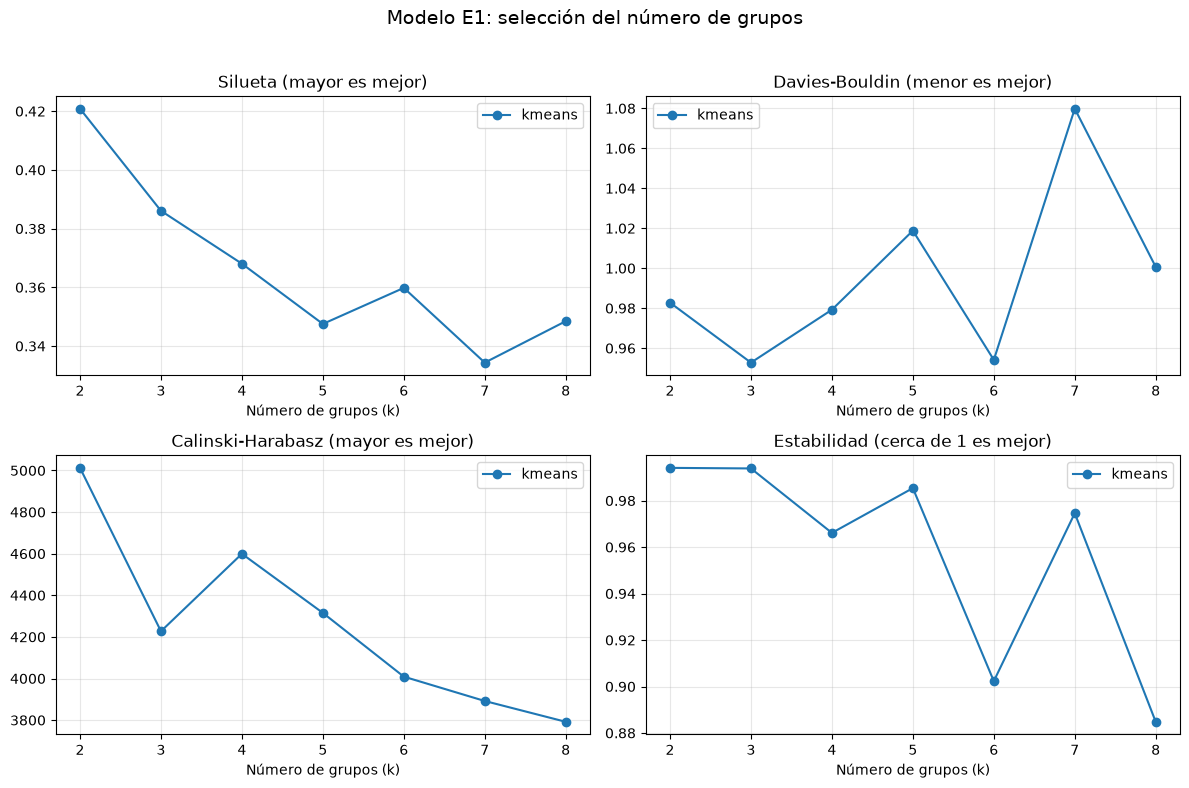

Modelo E1
          silueta  davies_bouldin  calinski_harabasz  estabilidad
metodo k                                                         
kmeans 2    0.421           0.983           5012.532        0.994
       3    0.386           0.953           4227.120        0.994
       4    0.368           0.979           4599.469        0.966
       5    0.348           1.019           4315.328        0.985
       6    0.360           0.954           4008.901        0.902
       7    0.334           1.080           3891.866        0.975
       8    0.348           1.001           3791.863        0.885



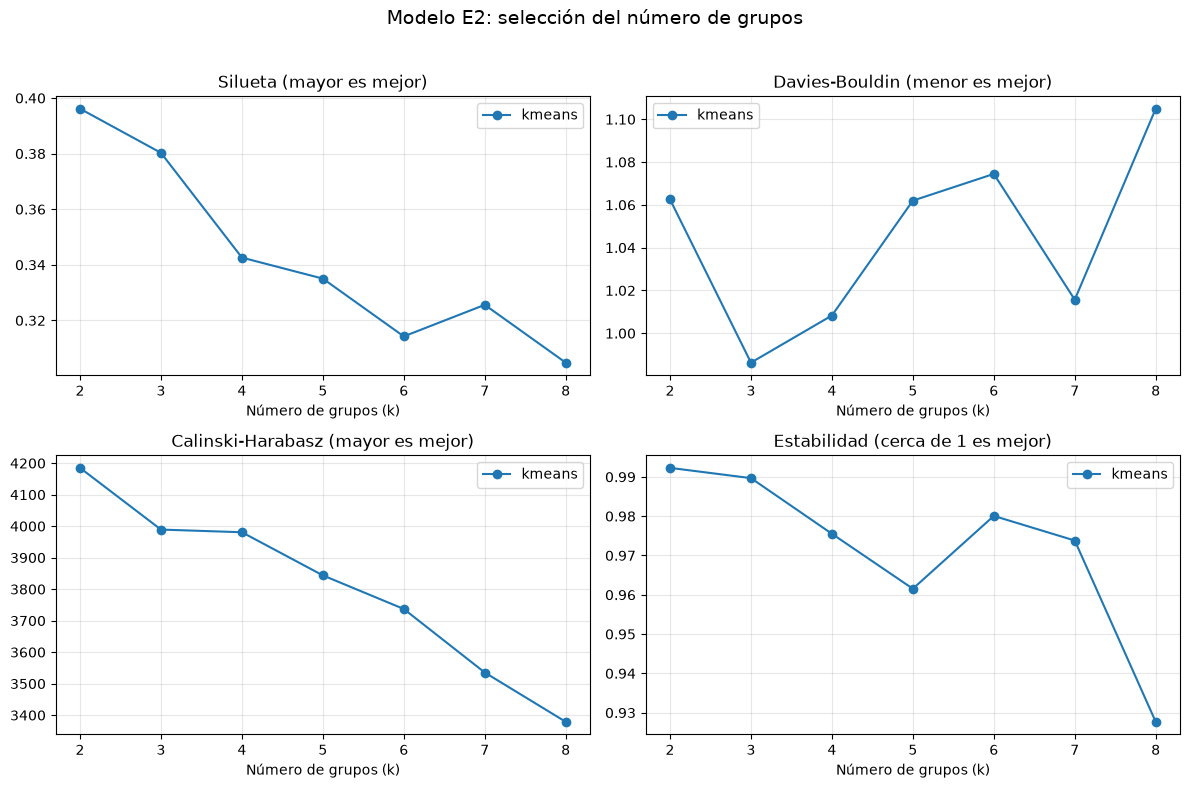

Modelo E2
          silueta  davies_bouldin  calinski_harabasz  estabilidad
metodo k                                                         
kmeans 2    0.396           1.063           4185.077        0.992
       3    0.380           0.986           3989.174        0.990
       4    0.343           1.008           3980.712        0.976
       5    0.335           1.062           3843.753        0.962
       6    0.314           1.074           3737.050        0.980
       7    0.326           1.016           3535.373        0.974
       8    0.305           1.105           3378.925        0.928



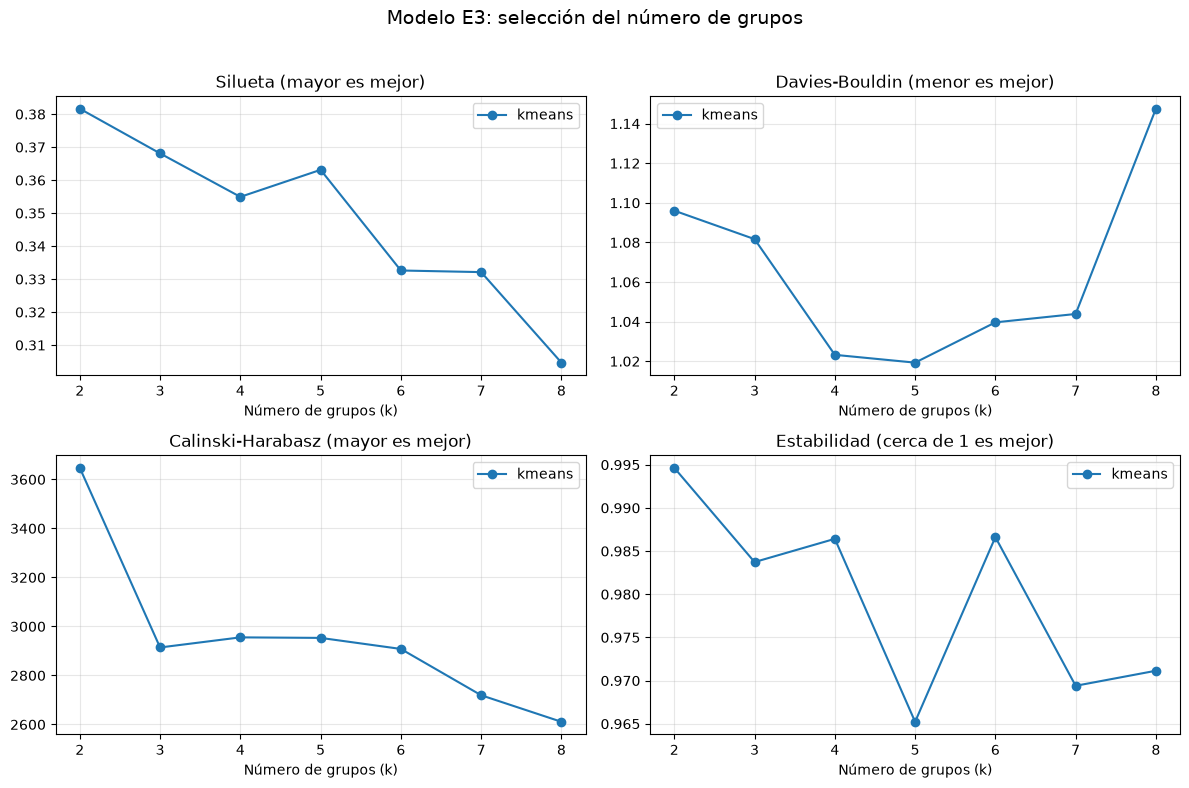

Modelo E3
          silueta  davies_bouldin  calinski_harabasz  estabilidad
metodo k                                                         
kmeans 2    0.382           1.096           3647.087        0.995
       3    0.368           1.082           2914.170        0.984
       4    0.355           1.023           2955.381        0.986
       5    0.363           1.019           2953.241        0.965
       6    0.333           1.040           2908.126        0.987
       7    0.332           1.044           2719.189        0.969
       8    0.305           1.148           2610.826        0.971



In [5]:
# Función para guardar las figuras en la carpeta de resultados.
def guardar(fig, nombre):
    if guardar_figuras:
        carpeta_fig = carpeta_salida / "figuras"
        carpeta_fig.mkdir(parents=True, exist_ok=True)
        fig.savefig(carpeta_fig / nombre, dpi=200, bbox_inches="tight")

# Métricas utilizadas para evaluar la calidad y estabilidad de los agrupamientos.
indices = [("silueta", "Silueta (mayor es mejor)"),
           ("davies_bouldin", "Davies-Bouldin (menor es mejor)"),
           ("calinski_harabasz", "Calinski-Harabasz (mayor es mejor)"),
           ("estabilidad", "Estabilidad (cerca de 1 es mejor)")]

# Representación gráfica y resumen de las métricas para cada modelo.
for m in modelos:
    metricas = resultados[m]["metricas"]
    fig, ejes = plt.subplots(2, 2, figsize=(12, 8))
    fig.suptitle(f"Modelo {m}: selección del número de grupos", fontsize=14)
    for eje, (columna, titulo) in zip(ejes.ravel(), indices):
        for metodo, g in metricas.groupby("metodo"):
            eje.plot(g["k"], g[columna], marker="o", label=metodo)
        eje.set_title(titulo)
        eje.set_xlabel("Número de grupos (k)")
        eje.set_xticks(list(rango_k))
        eje.grid(alpha=0.3)
        eje.legend()
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    guardar(fig, f"seleccion_k_modelo_{m}.png")
    plt.show()

    # Presentación de los valores de las métricas para cada K evaluado.
    print(f"Modelo {m}")
    print(metricas.set_index(["metodo", "k"]).round(3).to_string())
    print()

## 5. Asignación preliminar de grupos
Cuando no se especifica un número de grupos en `k_elegido`, se utiliza el valor de k con mayor silueta. Los grupos se numeran de mayor a menor tamaño.

In [6]:
# Selección del número de grupos para cada modelo.
def elegir_k(modelo):
    if k_elegido.get(modelo):
        return k_elegido[modelo]
    metricas = resultados[modelo]["metricas"]
    metricas = metricas[metricas["metodo"] == metodo_final]
    return int(metricas.loc[metricas["silueta"].idxmax(), "k"])


# Asignación de etiquetas según el tamaño de los grupos.
def asignar(modelo, k, metodo=None):
    """Asigna etiquetas consecutivas a los grupos, de mayor a menor tamaño."""
    metodo = metodo or metodo_final
    lab = agrupar(resultados[modelo]["X"], k, metodo, resultados[modelo]["Z"])
    orden = pd.Series(lab).value_counts().index
    nuevo = {viejo: i + 1 for i, viejo in enumerate(orden)}
    return pd.Series(lab, index=resultados[modelo]["datos"].index).map(nuevo)


# Determinación de k y asignación preliminar de grupos.
k_usado = {m: elegir_k(m) for m in modelos}
etiquetas = {m: asignar(m, k_usado[m]) for m in modelos}

# Advertencia cuando el número de grupos se selecciona automáticamente.
for m in modelos:
    if not k_elegido.get(m):
        print(f"Aviso: el k del modelo {m} es provisional ({k_usado[m]}). Revisar los gráficos antes de fijarlo.")

# Consolidación de las métricas de evaluación de los agrupamientos preliminares.
resumen = []
for m in modelos:
    X, lab = resultados[m]["X"], etiquetas[m].to_numpy()
    tabla_m = resultados[m]["metricas"]
    estab = tabla_m[(tabla_m["metodo"] == metodo_final) & (tabla_m["k"] == k_usado[m])]["estabilidad"]
    resumen.append({"modelo": m, "variables": len(modelos[m]), "metodo": metodo_final,
                    "k": k_usado[m],
                    "silueta": round(silhouette_score(X, lab), 3),
                    "davies_bouldin": round(davies_bouldin_score(X, lab), 3),
                    "calinski_harabasz": round(calinski_harabasz_score(X, lab), 1),
                    "estabilidad": round(float(estab.iloc[0]), 3)})

# Presentación del resumen comparativo de los modelos.
print()
print(pd.DataFrame(resumen).to_string(index=False))

Aviso: el k del modelo E1 es provisional (2). Revisar los gráficos antes de fijarlo.
Aviso: el k del modelo E2 es provisional (2). Revisar los gráficos antes de fijarlo.
Aviso: el k del modelo E3 es provisional (2). Revisar los gráficos antes de fijarlo.

modelo  variables metodo  k  silueta  davies_bouldin  calinski_harabasz  estabilidad
    E1          5 kmeans  2    0.421           0.983             5012.5        0.994
    E2          6 kmeans  2    0.396           1.063             4185.1        0.992
    E3          6 kmeans  2    0.382           1.096             3647.1        0.995


## 6. Gráficos de cada modelo
Para cada modelo se presentan:
1. Tamaño de los grupos.
2. Diagrama de Silueta: muestra el coeficiente de silueta de cada subpartida. Los valores positivos altos indican una mejor asignación al grupo, mientras que los negativos sugieren una posible asignación inadecuada. La línea roja representa la silueta promedio.
3. Proyección en dos dimensiones mediante PCA: permite visualizar la distribución de los grupos en el espacio de los dos primeros componentes principales.
4. Perfil de los grupos: promedio de cada variable estandarizada. Rojo indica que el grupo está por encima del promedio general y azul, por debajo.

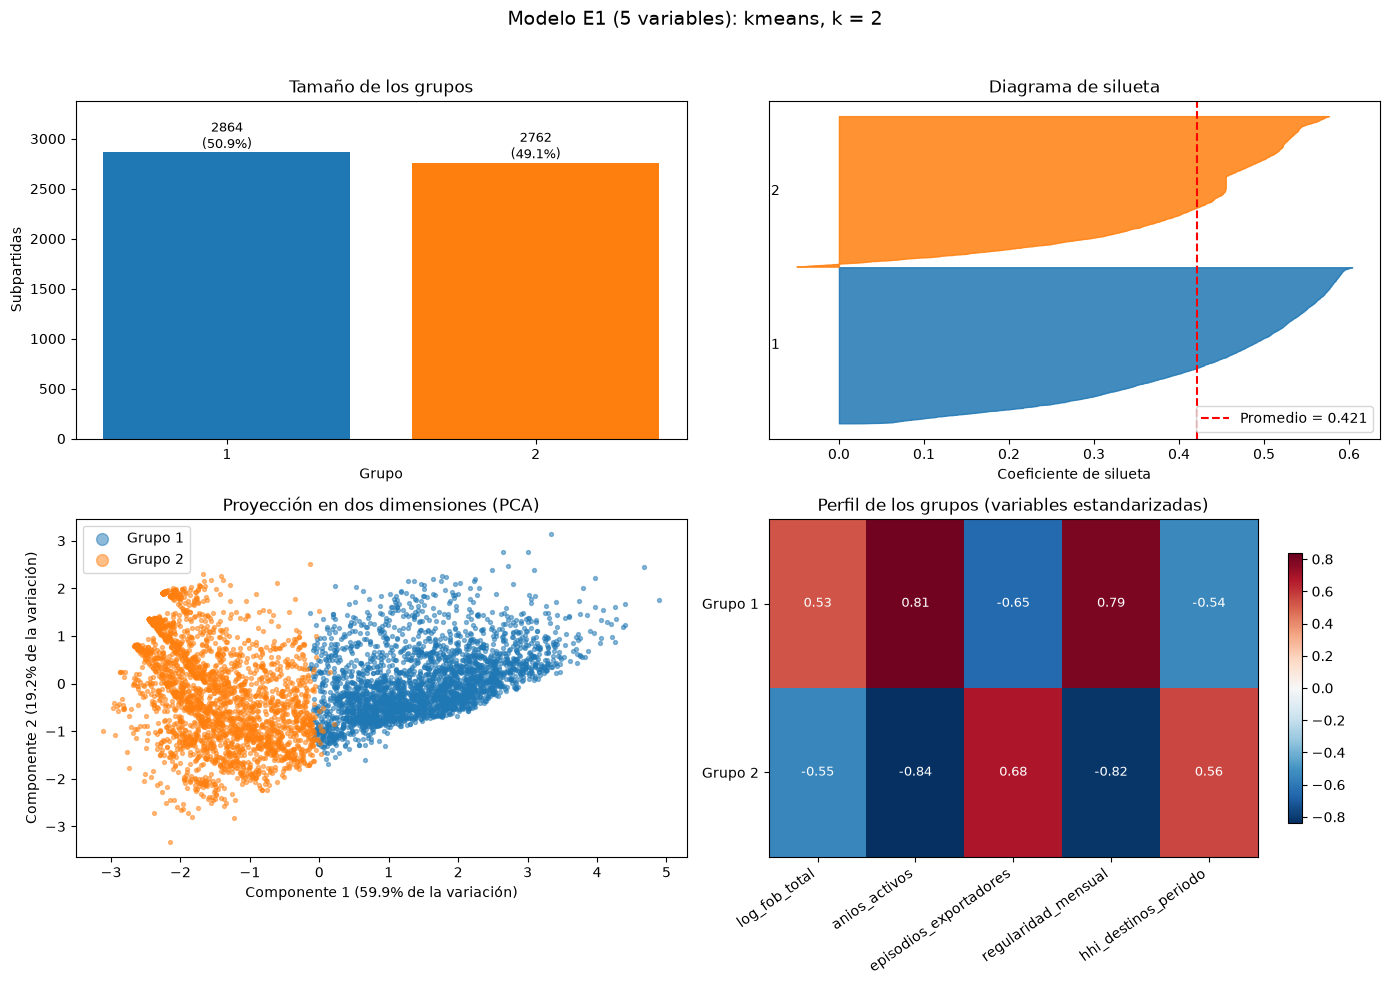

Promedios por grupo, modelo E1 (unidades originales)
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo
grupo                                                                                                              
1             2864           1.93           14.7                    1.13                 0.70                  0.34
2             2762           0.22            6.4                    2.67                 0.16                  0.64



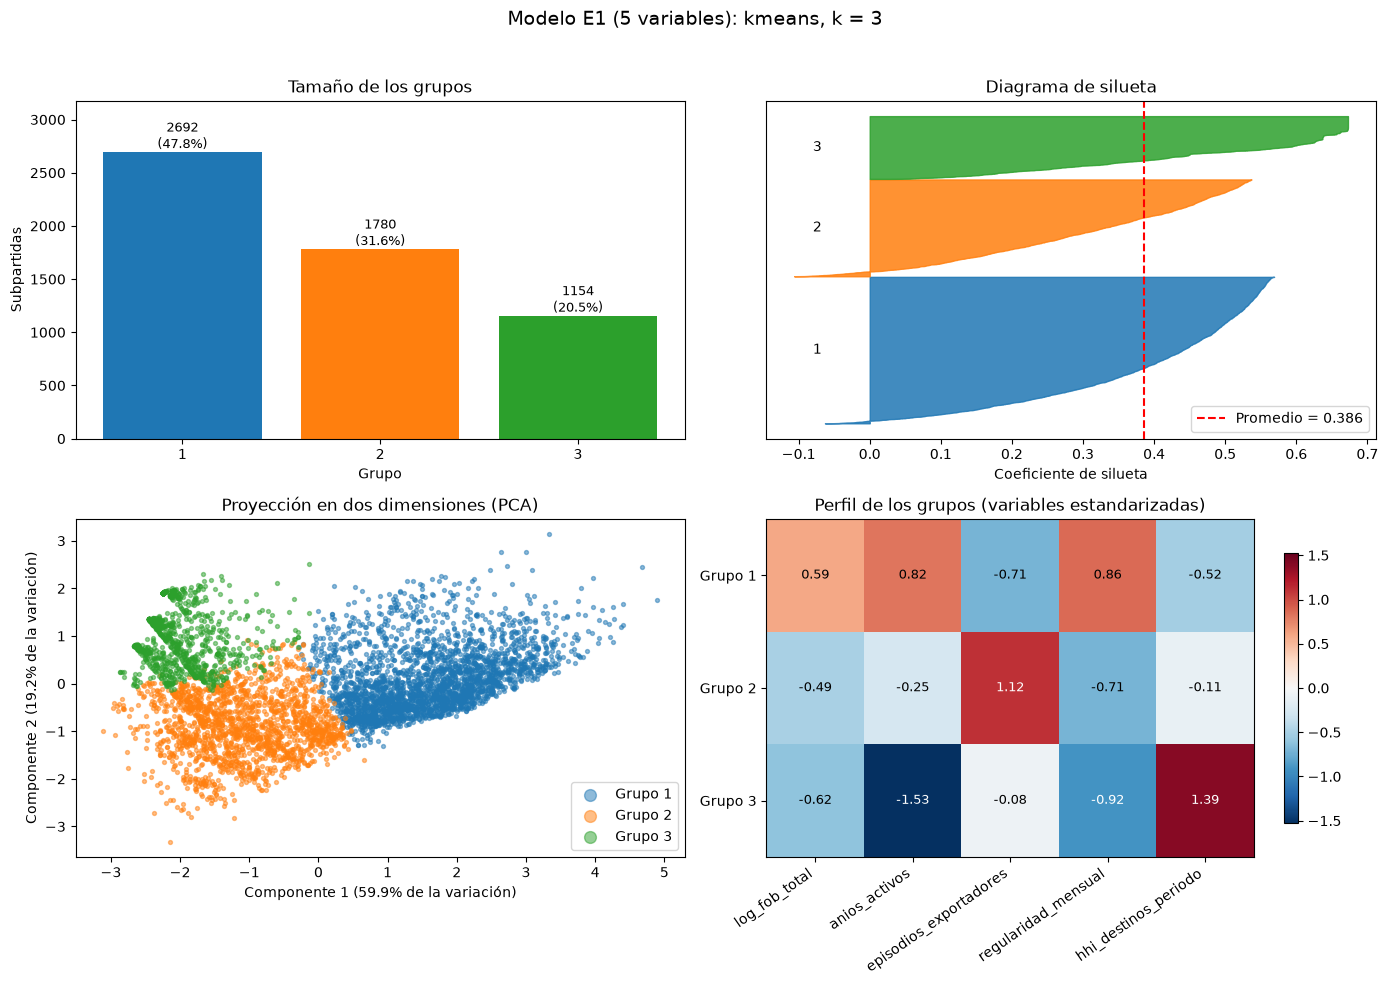

Promedios por grupo, modelo E1 (unidades originales)
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo
grupo                                                                                                              
1             2692           2.03          14.77                    1.07                 0.72                  0.34
2             1780           0.31           9.34                    3.19                 0.20                  0.46
3             1154           0.11           2.93                    1.79                 0.13                  0.88



In [7]:
# Paleta de colores para representar los grupos.
colores = plt.cm.tab10.colors


def graficar_modelo(modelo, k, metodo=None, mostrar=True):
    metodo = metodo or metodo_final
    datos = resultados[modelo]["datos"]
    X = resultados[modelo]["X"]
    columnas = modelos[modelo]
    lab = asignar(modelo, k, metodo).to_numpy()
    grupos = sorted(set(lab))
    k = len(grupos)

    fig, ejes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f"Modelo {modelo} ({len(columnas)} variables): {metodo}, k = {k}", fontsize=14)

    # 1. Distribución de las subpartidas por grupo.
    tamanos = pd.Series(lab).value_counts().sort_index()
    ejes[0, 0].bar(tamanos.index.astype(str), tamanos.values, color=[colores[g - 1] for g in tamanos.index])
    for i, v in enumerate(tamanos.values):
        ejes[0, 0].text(i, v, f"{v}\n({v / len(lab):.1%})", ha="center", va="bottom", fontsize=9)
    ejes[0, 0].set_title("Tamaño de los grupos")
    ejes[0, 0].set_xlabel("Grupo")
    ejes[0, 0].set_ylabel("Subpartidas")
    ejes[0, 0].set_ylim(0, tamanos.max() * 1.18)

    # 2. Distribución de los coeficientes de silueta por grupo.
    sil = silhouette_samples(X, lab)
    y_inicio = 10
    for g in grupos:
        s = np.sort(sil[lab == g])
        y_fin = y_inicio + len(s)
        ejes[0, 1].fill_betweenx(np.arange(y_inicio, y_fin), 0, s, color=colores[g - 1], alpha=0.85)
        ejes[0, 1].text(-0.08, y_inicio + len(s) / 2, str(g), va="center")
        y_inicio = y_fin + 10
    ejes[0, 1].axvline(sil.mean(), color="red", linestyle="--", label=f"Promedio = {sil.mean():.3f}")
    ejes[0, 1].set_title("Diagrama de silueta")
    ejes[0, 1].set_xlabel("Coeficiente de silueta")
    ejes[0, 1].set_yticks([])
    ejes[0, 1].legend(loc="lower right")

    # 3. Representación de los grupos mediante componentes principales (PCA).
    pca = PCA(n_components=2, random_state=semilla)
    P = pca.fit_transform(X)
    for g in grupos:
        punto = lab == g
        ejes[1, 0].scatter(P[punto, 0], P[punto, 1], s=8, alpha=0.5, color=colores[g - 1], label=f"Grupo {g}")
    ejes[1, 0].set_title("Proyección en dos dimensiones (PCA)")
    ejes[1, 0].set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.1%} de la variación)")
    ejes[1, 0].set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.1%} de la variación)")
    ejes[1, 0].legend(markerscale=3)

    # 4. Perfil promedio de los grupos en las variables estandarizadas.
    perfil = pd.DataFrame(X, columns=columnas).groupby(lab).mean()
    tope = np.abs(perfil.values).max()
    imagen = ejes[1, 1].imshow(perfil.values, cmap="RdBu_r", vmin=-tope, vmax=tope, aspect="auto")
    ejes[1, 1].set_xticks(range(len(columnas)))
    ejes[1, 1].set_xticklabels(columnas, rotation=35, ha="right")
    ejes[1, 1].set_yticks(range(k))
    ejes[1, 1].set_yticklabels([f"Grupo {g}" for g in perfil.index])
    for i in range(perfil.shape[0]):
        for j in range(perfil.shape[1]):
            valor = perfil.values[i, j]
            color_texto = "white" if abs(valor) > 0.6 * tope else "black"
            ejes[1, 1].text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=9, color=color_texto)
    ejes[1, 1].set_title("Perfil de los grupos (variables estandarizadas)")
    fig.colorbar(imagen, ax=ejes[1, 1], shrink=0.8)

    # Ajuste, almacenamiento y presentación de la figura.
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    guardar(fig, f"modelo_{modelo}_{metodo}_k{k}.png")
    if mostrar:
        plt.show()
    else:
        plt.close(fig)

    # Promedios de los indicadores antes de la estandarización.
    if mostrar:
        tabla = datos.assign(grupo=lab).groupby("grupo")[columnas].mean().round(2)
        tabla.insert(0, "subpartidas", tamanos)
        print(f"Promedios por grupo, modelo {modelo} (sin estandarizar)")
        print(tabla.to_string())
        print()


# Generación de gráficos y perfiles del modelo E1.
graficar_modelo("E1", 2)  # Figura 12 de la tesis
graficar_modelo("E1", 3)  # Figura 13 de la tesis

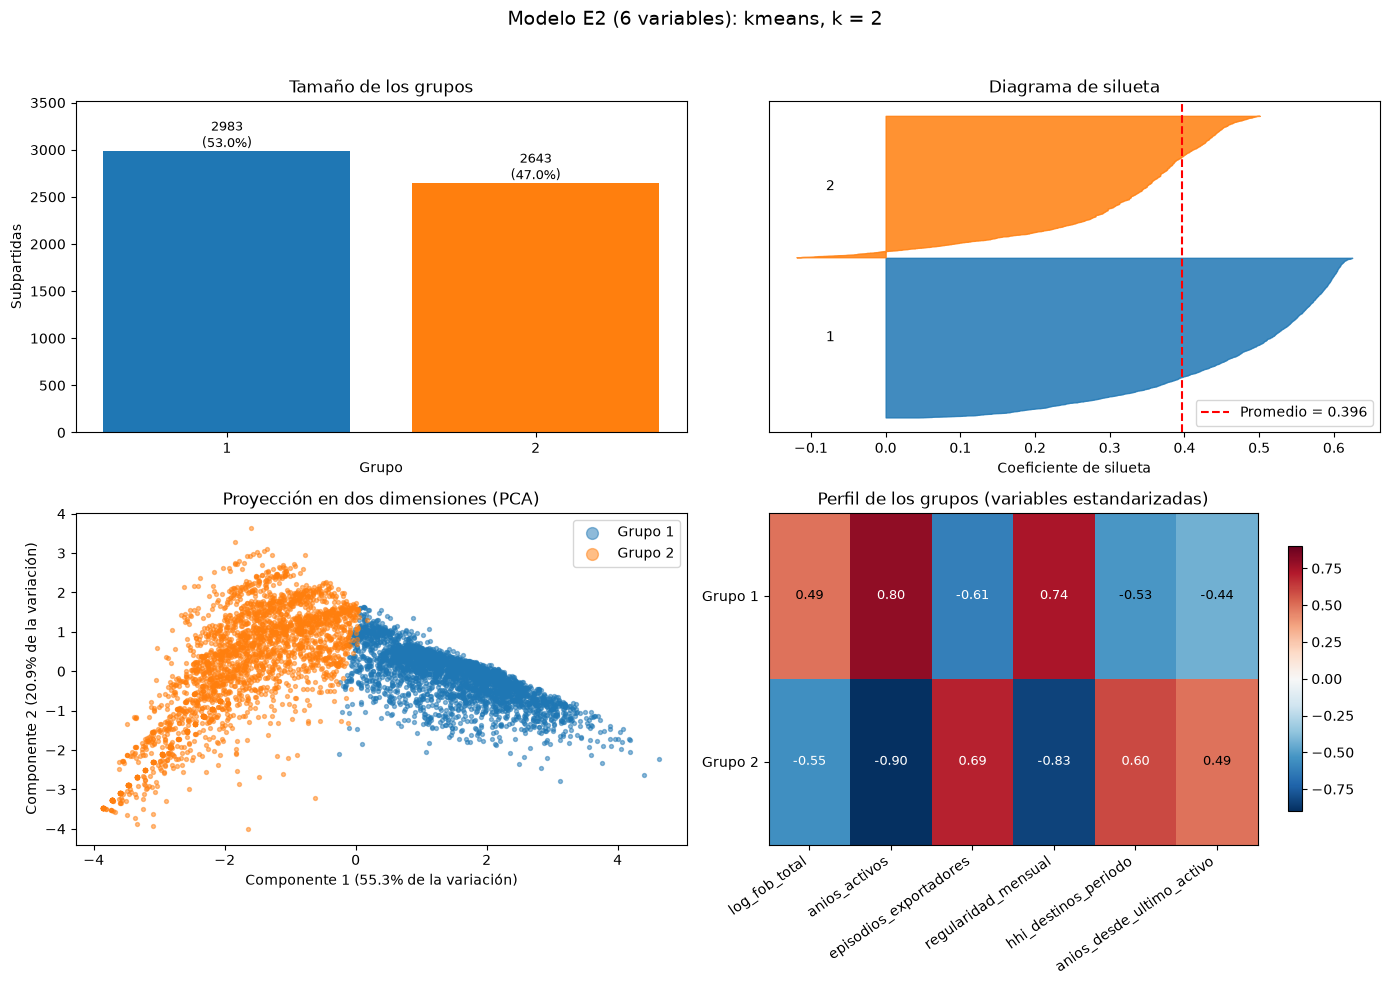

Promedios por grupo, modelo E2 (unidades originales)
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo  anios_desde_ultimo_activo
grupo                                                                                                                                         
1             2983           1.87          14.64                    1.18                 0.68                  0.34                       0.04
2             2643           0.21           6.08                    2.69                 0.16                  0.65                       2.63



In [8]:
# Generación de gráficos y perfiles del modelo E2.
graficar_modelo("E2", k_usado["E2"])

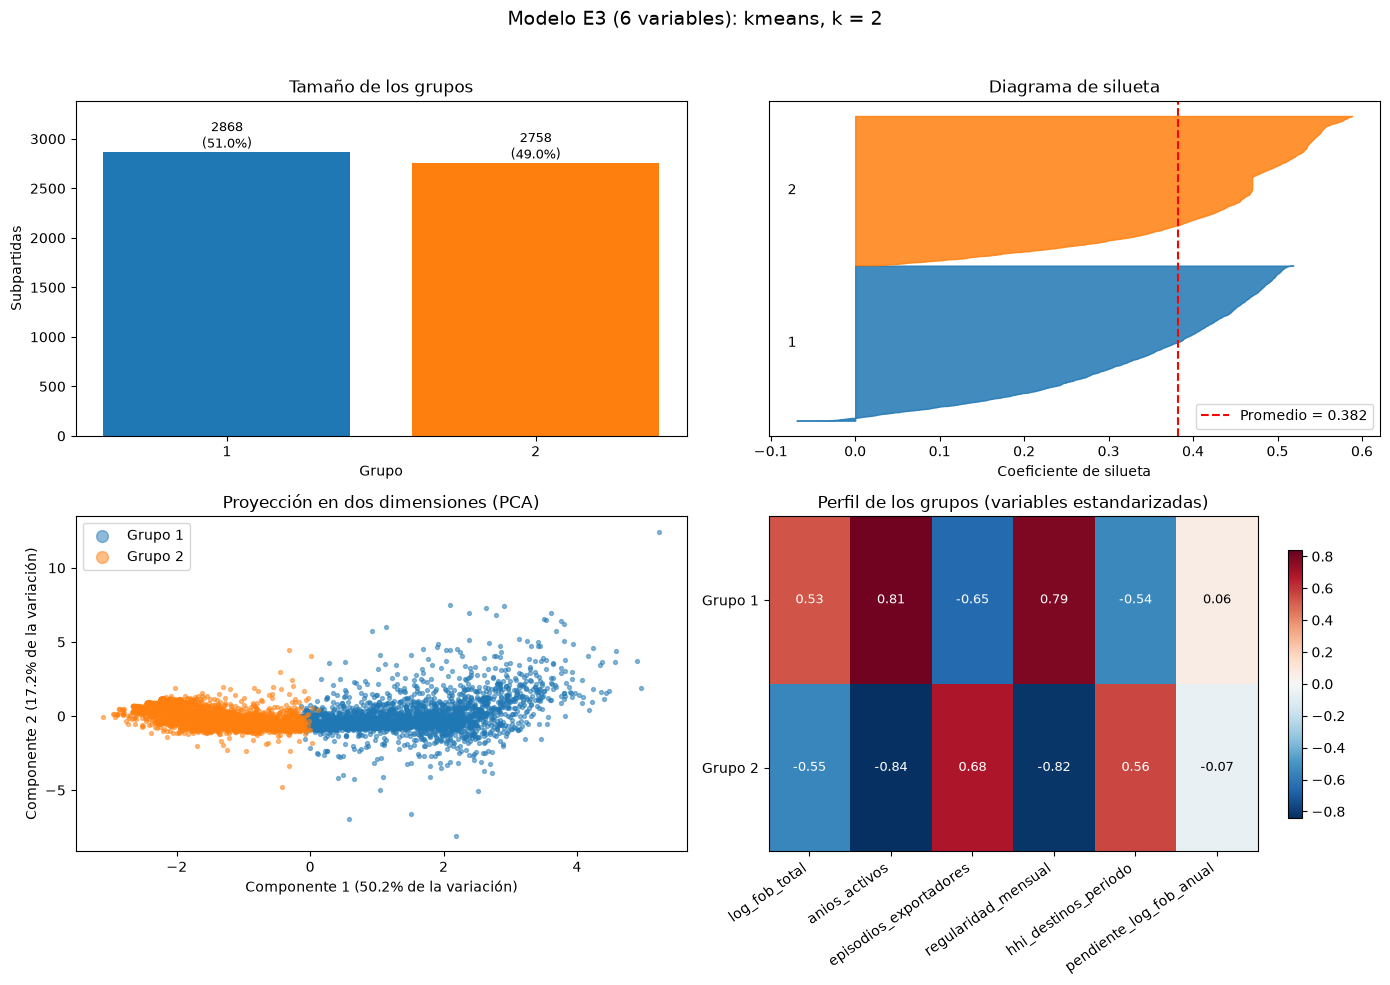

Promedios por grupo, modelo E3 (unidades originales)
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo  pendiente_log_fob_anual
grupo                                                                                                                                       
1             2868           1.93          14.69                    1.14                 0.70                  0.34                      0.0
2             2758           0.22           6.39                    2.67                 0.16                  0.64                     -0.0



In [9]:
# Generación de gráficos y perfiles del modelo E3.
graficar_modelo("E3", k_usado["E3"])

### Gráficos de los demás valores de k
Se guardan en la carpeta `figuras` los mismos cuatro gráficos para todos los k de `rango_k`, con k-means, para poder compararlos sin volver a ejecutar.
Los archivos se llaman `modelo_E1_kmeans_k3.png`, `modelo_E2_kmeans_k5.png`, etc.

In [10]:
# Generación y almacenamiento de gráficos para todos los valores de K evaluados.
if guardar_figuras and guardar_todos_los_k:
    for m in modelos:
        for metodo in metodos:
            for k in rango_k:
                graficar_modelo(m, k, metodo, mostrar=False)
    print("Gráficos guardados en:", (carpeta_salida / "figuras").resolve())
else:
    print("No se guardaron los gráficos de los demás k.")

Gráficos guardados en: C:\Users\Udep titulación\Downloads\Cuadernos finales\resultados\clustering\figuras


## Comparación de las configuraciones mediante ARI

Se comparan las asignaciones obtenidas con E1, E2 y E3 para las soluciones de dos y tres grupos.

In [11]:

# Comparación de las configuraciones para dos y tres grupos
pares = [("E1", "E2"), ("E1", "E3"), ("E2", "E3")]
tabla_ari = pd.DataFrame(index=["E1 y E2", "E1 y E3", "E2 y E3"])

for k in (2, 3):
    grupos = {modelo: asignar(modelo, k) for modelo in modelos}
    valores_ari = []

    for a, b in pares:
        assert grupos[a].index.equals(grupos[b].index)
        valores_ari.append(adjusted_rand_score(grupos[a], grupos[b]))

    tabla_ari[f"k={k}"] = valores_ari

tabla_ari.index.name = "Configuraciones comparadas"
display(tabla_ari.round(4))
tabla_ari.to_csv(carpeta_salida / "ari_entre_configuraciones.csv")


,k=2,k=3
Configuraciones comparadas,,
E1 y E2,0.9077,0.8511
E1 y E3,0.9943,0.4788
E2 y E3,0.9117,0.5009


## Comparación de E1, E2 y E3 con tres grupos

Se fija k = 3 en las tres configuraciones y se comparan los promedios de sus indicadores por grupo.

In [12]:
# Asignación de grupos para k=3 en cada modelo
k_analisis = {m: 3 for m in modelos}
etiquetas_k = {m: asignar(m, k_analisis[m]) for m in modelos}

### Promedios de los indicadores por grupo y configuración

In [13]:
# Cálculo y presentación de los perfiles promedio de los grupos para cada modelo.
for m in modelos:
    datos = resultados[m]["datos"]
    lab = etiquetas_k[m]
    tabla = datos.assign(grupo=lab).groupby("grupo")[modelos[m]].mean().round(4)
    tabla.insert(0, "subpartidas", lab.value_counts().sort_index())
    print(f"Modelo {m}, k = {k_analisis[m]}")
    print(tabla.to_string())
    print()

Modelo E1, k = 3
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo
grupo                                                                                                              
1             2692         2.0261        14.7675                  1.0732               0.7247                0.3397
2             1780         0.3132         9.3404                  3.1865               0.1974                0.4564
3             1154         0.1125         2.9289                  1.7938               0.1280                0.8769

Modelo E2, k = 3
       subpartidas  log_fob_total  anios_activos  episodios_exportadores  regularidad_mensual  hhi_destinos_periodo  anios_desde_ultimo_activo
grupo                                                                                                                                         
1             2713         2.0116        14.7788                  1.0822               0.7212      

## Exportación de la solución definitiva: E1 con tres grupos

In [14]:
# 1. Recuperación de los indicadores y las etiquetas definitivas de E1.
base_final = resultados["E1"]["datos"].copy()

base_final["grupo_E1"] = (
    etiquetas_k["E1"]
    .reindex(base_final.index)
)

# 2. Validación de la cantidad de registros, las etiquetas y los resultados esperados.
assert k_analisis["E1"] == 3
assert len(base_final) == 5626
assert base_final["grupo_E1"].notna().all()

base_final["grupo_E1"] = base_final["grupo_E1"].astype(int)

conteo = base_final["grupo_E1"].value_counts().sort_index()

assert conteo.to_dict() == {
    1: 2692,
    2: 1780,
    3: 1154
}, "Los tamaños de los grupos no coinciden."

assert base_final["subpartida_homologada"].nunique() == 5626

fob_total = base_final["fob_total_mill"].sum()

assert abs(fob_total - 706350.99034) < 0.01

# 3. Carpeta de salida de la clasificación final
carpeta = carpeta_salida

# 4. Exportación de los resultados en formatos Parquet y CSV.
base_final.to_parquet(
    carpeta / "subpartidas_E1_k3_FINAL.parquet",
    index=False
)

base_final.to_csv(
    carpeta / "subpartidas_E1_k3_FINAL.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. Resumen de resultados.
print("RESULTADOS DEFINITIVOS DE E1")
print("\nSubpartidas:", len(base_final))
print("\nSubpartidas por grupo:")
print(conteo.to_string())
print("\nFOB total:", round(fob_total, 2))
print("\nArchivos guardados en:")
print(carpeta)


RESULTADOS DEFINITIVOS DE E1

Subpartidas: 5626

Subpartidas por grupo:
grupo_E1
1    2692
2    1780
3    1154

FOB total: 706350.99

Archivos guardados en:
resultados\clustering


## Redistribución de las subpartidas entre configuraciones

Se compara la distribución de las subpartidas de cada grupo de E1 al incorporar la recencia exportadora (E2) y la tendencia del FOB anual (E3).

E1 frente a E2 - ARI: 0.8511


col_0,1,2,3
row_0,,,
1,2682,4,6
2,27,1713,40
3,4,329,821


E1 frente a E3 - ARI: 0.4788


col_0,1,2,3
row_0,,,
1,0,2197,495
2,1458,320,2
3,1146,7,1


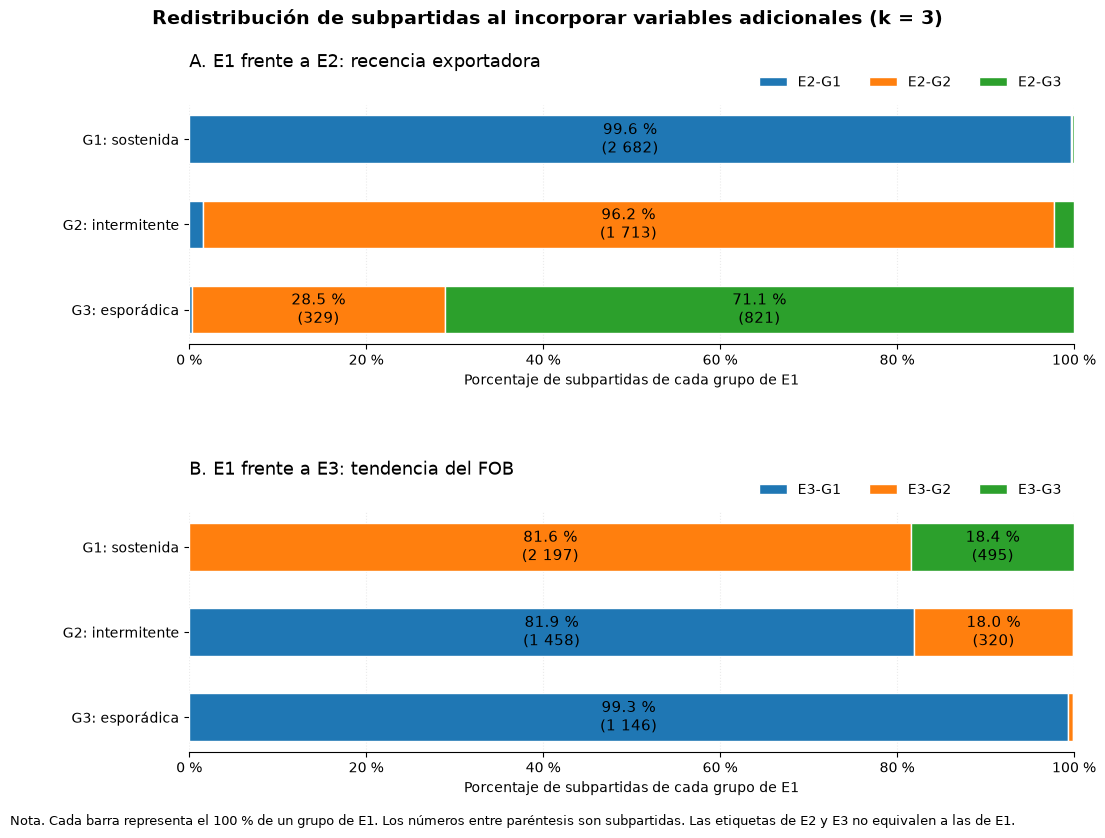

In [15]:
orden = [1, 2, 3]
nombres_E1 = ["G1: sostenida", "G2: intermitente", "G3: esporádica"]
cruces = {}

for modelo in ["E2", "E3"]:
    tabla = pd.crosstab(etiquetas_k["E1"], etiquetas_k[modelo])
    tabla = tabla.reindex(index=orden, columns=orden, fill_value=0)
    cruces[modelo] = tabla

    tabla.to_csv(
        carpeta_salida / f"cruce_E1_{modelo}_k3.csv",
        encoding="utf-8-sig"
    )

    ari = adjusted_rand_score(etiquetas_k["E1"], etiquetas_k[modelo])
    print(f"E1 frente a {modelo} - ARI: {ari:.4f}")
    display(tabla)

fig, ejes = plt.subplots(2, 1, figsize=(11.2, 8.3))

for eje, modelo, titulo in zip(
    ejes,
    ["E2", "E3"],
    ["A. E1 frente a E2: recencia exportadora",
     "B. E1 frente a E3: tendencia del FOB"]
):
    tabla = cruces[modelo]
    porcentaje = tabla.div(tabla.sum(axis=1), axis=0) * 100
    izquierda = np.zeros(3)

    for grupo in orden:
        valores = porcentaje[grupo].to_numpy()

        eje.barh(
            nombres_E1, valores, left=izquierda,
            height=0.56, label=f"{modelo}-G{grupo}",
            edgecolor="white", linewidth=1
        )

        for i, valor in enumerate(valores):
            if valor >= 9:
                n = int(tabla.iloc[i][grupo])
                eje.text(
                    izquierda[i] + valor / 2, i,
                    f"{valor:.1f} %\n({n:,})".replace(",", " "),
                    ha="center", va="center", fontsize=11
                )

        izquierda += valores

    eje.invert_yaxis()
    eje.set_xlim(0, 100)
    eje.set_xticks(
        range(0, 101, 20),
        [f"{v} %" for v in range(0, 101, 20)]
    )
    eje.set_title(titulo, loc="left", fontsize=13, pad=27)
    eje.set_xlabel("Porcentaje de subpartidas de cada grupo de E1")
    eje.legend(
        ncol=3, loc="lower right",
        bbox_to_anchor=(1, 1.01), frameon=False
    )
    eje.grid(axis="x", linestyle=":", alpha=0.25)
    eje.set_axisbelow(True)
    eje.spines[["top", "right", "left"]].set_visible(False)

fig.suptitle(
    "Redistribución de subpartidas al incorporar variables adicionales (k = 3)",
    fontsize=14, fontweight="bold", y=0.995
)

fig.text(
    0.02, 0.012,
    "Nota. Cada barra representa el 100 % de un grupo de E1. "
    "Los números entre paréntesis son subpartidas. "
    "Las etiquetas de E2 y E3 no equivalen a las de E1.",
    fontsize=9
)

fig.subplots_adjust(
    left=0.18, right=0.97,
    top=0.88, bottom=0.10, hspace=0.70
)

carpeta_figuras = carpeta_salida / "figuras"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

fig.savefig(
    carpeta_figuras / "comparacion_E1_E2_E3_k3.png",
    dpi=300, bbox_inches="tight"
)

fig.savefig(
    carpeta_figuras / "comparacion_E1_E2_E3_k3.svg",
    bbox_inches="tight"
)

plt.show()


## Correspondencia entre los grupos de E1, E2 y E3 mediante diagramas de flujo

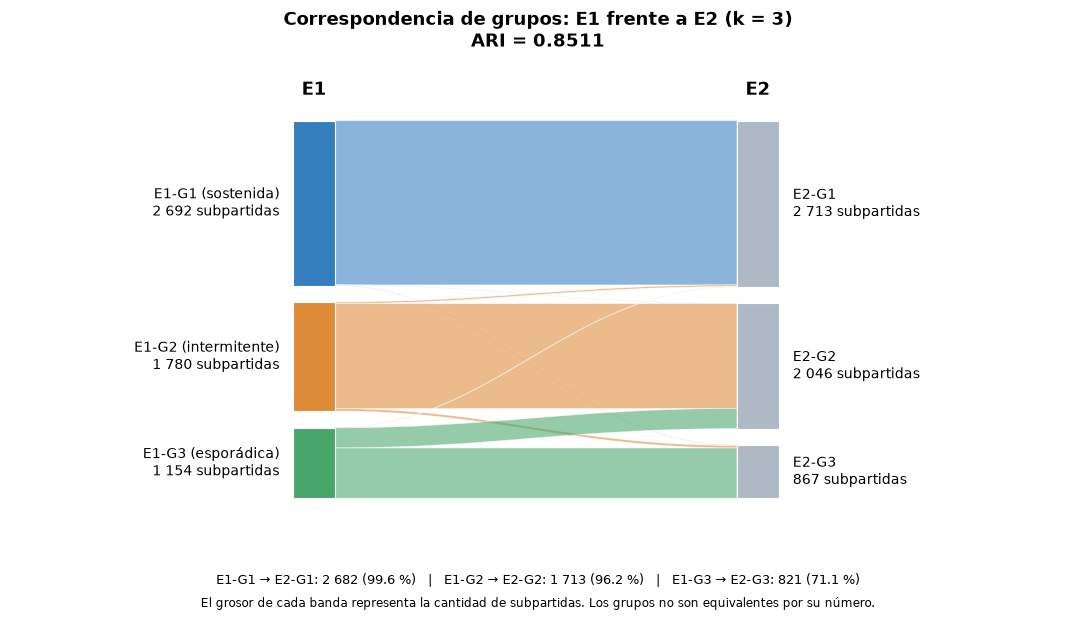

E1 frente a E2 | ARI: 0.8511


col_0,1,2,3
row_0,,,
1,2682,4,6
2,27,1713,40
3,4,329,821


Guardado en: resultados\clustering\figuras\flujo_E1_E2_k3.png


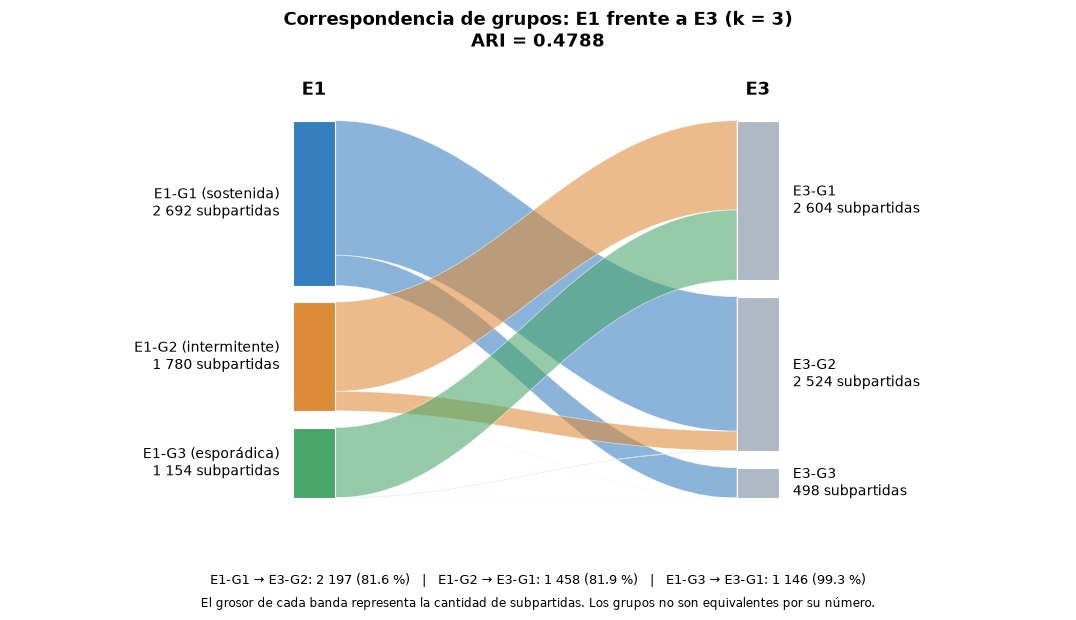

E1 frente a E3 | ARI: 0.4788


col_0,1,2,3
row_0,,,
1,0,2197,495
2,1458,320,2
3,1146,7,1


Guardado en: resultados\clustering\figuras\flujo_E1_E3_k3.png


In [17]:
pares = [("E1", "E2"), ("E1", "E3")]
colores_flujo = ["#357EBE", "#DE8B37", "#48A66A"]
carpeta_figuras = carpeta_salida / "figuras"
carpeta_figuras.mkdir(parents=True, exist_ok=True)

def grafico_flujo(origen, destino):
    a, b = etiquetas_k[origen], etiquetas_k[destino]
    assert a.index.equals(b.index), "Las subpartidas no están alineadas."

    tabla = pd.crosstab(a, b).reindex(
        index=[1, 2, 3], columns=[1, 2, 3], fill_value=0
    )
    total = tabla.to_numpy().sum()
    ari = adjusted_rand_score(a, b)
    escala = 0.73 / total
    espacio = 0.035

    def posiciones(tamanos):
        superior = 0.91
        cajas = {}
        for grupo, cantidad in enumerate(tamanos, 1):
            alto = cantidad * escala
            cajas[grupo] = (superior - alto, superior)
            superior -= alto + espacio
        return cajas

    izq = posiciones(tabla.sum(axis=1))
    der = posiciones(tabla.sum(axis=0))
    inicio_izq = {g: izq[g][1] for g in (1, 2, 3)}
    inicio_der = {g: der[g][1] for g in (1, 2, 3)}

    fig, ax = plt.subplots(figsize=(12, 6.4))
    x0, x1, ancho = 0.18, 0.76, 0.055

    for i in (1, 2, 3):
        for j in (1, 2, 3):
            n = int(tabla.loc[i, j])
            if n == 0:
                continue

            alto = n * escala
            a1, a0 = inicio_izq[i], inicio_izq[i] - alto
            b1, b0 = inicio_der[j], inicio_der[j] - alto
            inicio_izq[i] = a0
            inicio_der[j] = b0

            codigos = [
                Ruta.MOVETO,
                Ruta.CURVE4, Ruta.CURVE4, Ruta.CURVE4,
                Ruta.LINETO,
                Ruta.CURVE4, Ruta.CURVE4, Ruta.CURVE4,
                Ruta.CLOSEPOLY
            ]
            vertices = [
                (x0 + ancho, a1),
                (0.44, a1), (0.54, b1), (x1, b1),
                (x1, b0),
                (0.54, b0), (0.44, a0), (x0 + ancho, a0),
                (x0 + ancho, a1)
            ]

            ax.add_patch(
                PathPatch(
                    Ruta(vertices, codigos),
                    facecolor=colores_flujo[i - 1],
                    edgecolor="white",
                    linewidth=0.55,
                    alpha=0.58
                )
            )

    for lado, cajas, grupos in [
        (origen, izq, tabla.sum(axis=1)),
        (destino, der, tabla.sum(axis=0))
    ]:
        izquierda = x0 if lado == origen else x1

        for g in (1, 2, 3):
            inferior, superior = cajas[g]

            ax.add_patch(
                Rectangle(
                    (izquierda, inferior),
                    ancho,
                    superior - inferior,
                    facecolor=colores_flujo[g - 1] if lado == origen else "#AEB9C5",
                    edgecolor="white",
                    linewidth=0.8
                )
            )

            cantidad = f"{int(grupos.loc[g]):,}".replace(",", " ")
            nombre = f"{lado}-G{g}"

            if lado == "E1":
                nombre += [
                    " (sostenida)",
                    " (intermitente)",
                    " (esporádica)"
                ][g - 1]

            etiqueta = f"{nombre}\n{cantidad} subpartidas"

            ax.text(
                izquierda - 0.018 if lado == origen else izquierda + ancho + 0.018,
                (inferior + superior) / 2,
                etiqueta,
                ha="right" if lado == origen else "left",
                va="center",
                fontsize=10.2
            )

    ax.text(x0 + ancho / 2, 0.975, origen,
            ha="center", va="center", fontsize=13, fontweight="bold")
    ax.text(x1 + ancho / 2, 0.975, destino,
            ha="center", va="center", fontsize=13, fontweight="bold")

    ax.set_xlim(-0.19, 1.19)
    ax.set_ylim(0.03, 1.02)
    ax.axis("off")

    ax.set_title(
        f"Correspondencia de grupos: {origen} frente a {destino} (k = 3)\n"
        f"ARI = {ari:.4f}",
        fontsize=13, fontweight="bold", pad=16
    )

    resumen = []
    for i in (1, 2, 3):
        j = int(tabla.loc[i].idxmax())
        n = int(tabla.loc[i, j])
        porcentaje = 100 * n / int(tabla.loc[i].sum())

        resumen.append(
            f"{origen}-G{i} → {destino}-G{j}: "
            f"{n:,} ({porcentaje:.1f} %)".replace(",", " ")
        )

    fig.text(0.50, 0.065, "   |   ".join(resumen),
             ha="center", fontsize=9.3)

    fig.text(
        0.50, 0.029,
        "El grosor de cada banda representa la cantidad de subpartidas. "
        "Los grupos no son equivalentes por su número.",
        ha="center", fontsize=8.9
    )

    fig.subplots_adjust(
        left=0.06, right=0.94, top=0.87, bottom=0.14
    )

    ruta = carpeta_figuras / f"flujo_{origen}_{destino}_k3.png"
    fig.savefig(ruta, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"{origen} frente a {destino} | ARI: {ari:.4f}")
    display(tabla)
    print("Guardado en:", ruta)

for origen, destino in pares:
    grafico_flujo(origen, destino)
